# Blood Cell Type Classification Using Microscopy
**Deep Learning · Medical Image Classification · AIDL Project**

Dataset: **BloodMNIST** (MedMNIST) - 8 classes, official train / validation / test splits.
Models: **ResNet-18**, **DenseNet-121**, **EfficientNet-B0** (all ImageNet-pretrained CNNs).
Best model is selected by **validation macro-F1**. All numbers in the tables and graphs come from the run itself; nothing is hard-coded.


## 1. Install and import libraries

In [ ]:
!pip install -q medmnist scikit-learn seaborn pandas matplotlib

In [ ]:
import os, time, copy, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms, models

import medmnist
from medmnist import INFO

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    cohen_kappa_score, matthews_corrcoef,
    classification_report, precision_recall_fscore_support
)
from sklearn.preprocessing import label_binarize

sns.set_style("whitegrid")
print("PyTorch:", torch.__version__)
print("MedMNIST:", medmnist.__version__)

PyTorch: 2.14.1+cu130
MedMNIST: 3.0.2


## 2. Configuration

In [ ]:
SEED = 42
DATA_FLAG = "bloodmnist"
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
EARLY_STOP_PATIENCE = 5
NUM_WORKERS = 0  # 0 avoids the Colab multiprocessing cleanup warnings

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU found. Training will be very slow. Enable a GPU runtime.")

USE_GOOGLE_DRIVE = True    # True = keep checkpoints/results on Google Drive so they survive a disconnect
RESUME = False             # False = fresh experiment. Set True ONLY to continue an interrupted run with the same settings and the same Drive folder

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = "/content/drive/MyDrive/BloodMNIST_outputs"
else:
    OUTPUT_DIR = "outputs"
CKPT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
RES_DIR = os.path.join(OUTPUT_DIR, "results")
for d in (CKPT_DIR, FIG_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

Device: cuda
GPU: Tesla T4
Mounted at /content/drive


## 3. Load BloodMNIST with the official splits

In [ ]:
info = INFO[DATA_FLAG]
DataClass = getattr(medmnist, info["python_class"])
NUM_CLASSES = len(info["label"])

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Augmentation only for training data
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# No random augmentation for validation / test
test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_dataset = DataClass(split="train", transform=train_transform, download=True, size=IMAGE_SIZE, as_rgb=True)
val_dataset   = DataClass(split="val",   transform=test_transform,  download=True, size=IMAGE_SIZE, as_rgb=True)
test_dataset  = DataClass(split="test",  transform=test_transform,  download=True, size=IMAGE_SIZE, as_rgb=True)

print("Task:", info["task"])
print("Classes:", NUM_CLASSES)
print("Train:", len(train_dataset), "| Val:", len(val_dataset), "| Test:", len(test_dataset))
print("Total:", len(train_dataset) + len(val_dataset) + len(test_dataset))
print("Original labels:", info["label"])

def get_labels(dataset):
    return dataset.labels.flatten().astype(int)

# Short names used ONLY for plots (training uses the original labels)
display_names = [
    "Basophil", "Eosinophil", "Erythroblast", "Immature granulocytes",
    "Lymphocyte", "Monocyte", "Neutrophil", "Platelet"
]

100%|██████████| 1.54G/1.54G [01:16<00:00, 20.2MB/s]


Task: multi-class
Classes: 8
Train: 11959 | Val: 1712 | Test: 3421
Total: 17092
Original labels: {'0': 'basophil', '1': 'eosinophil', '2': 'erythroblast', '3': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', '4': 'lymphocyte', '5': 'monocyte', '6': 'neutrophil', '7': 'platelet'}


## 4. Dataset visualizations

### Cell 9 (corrected) - Sample blood-cell images

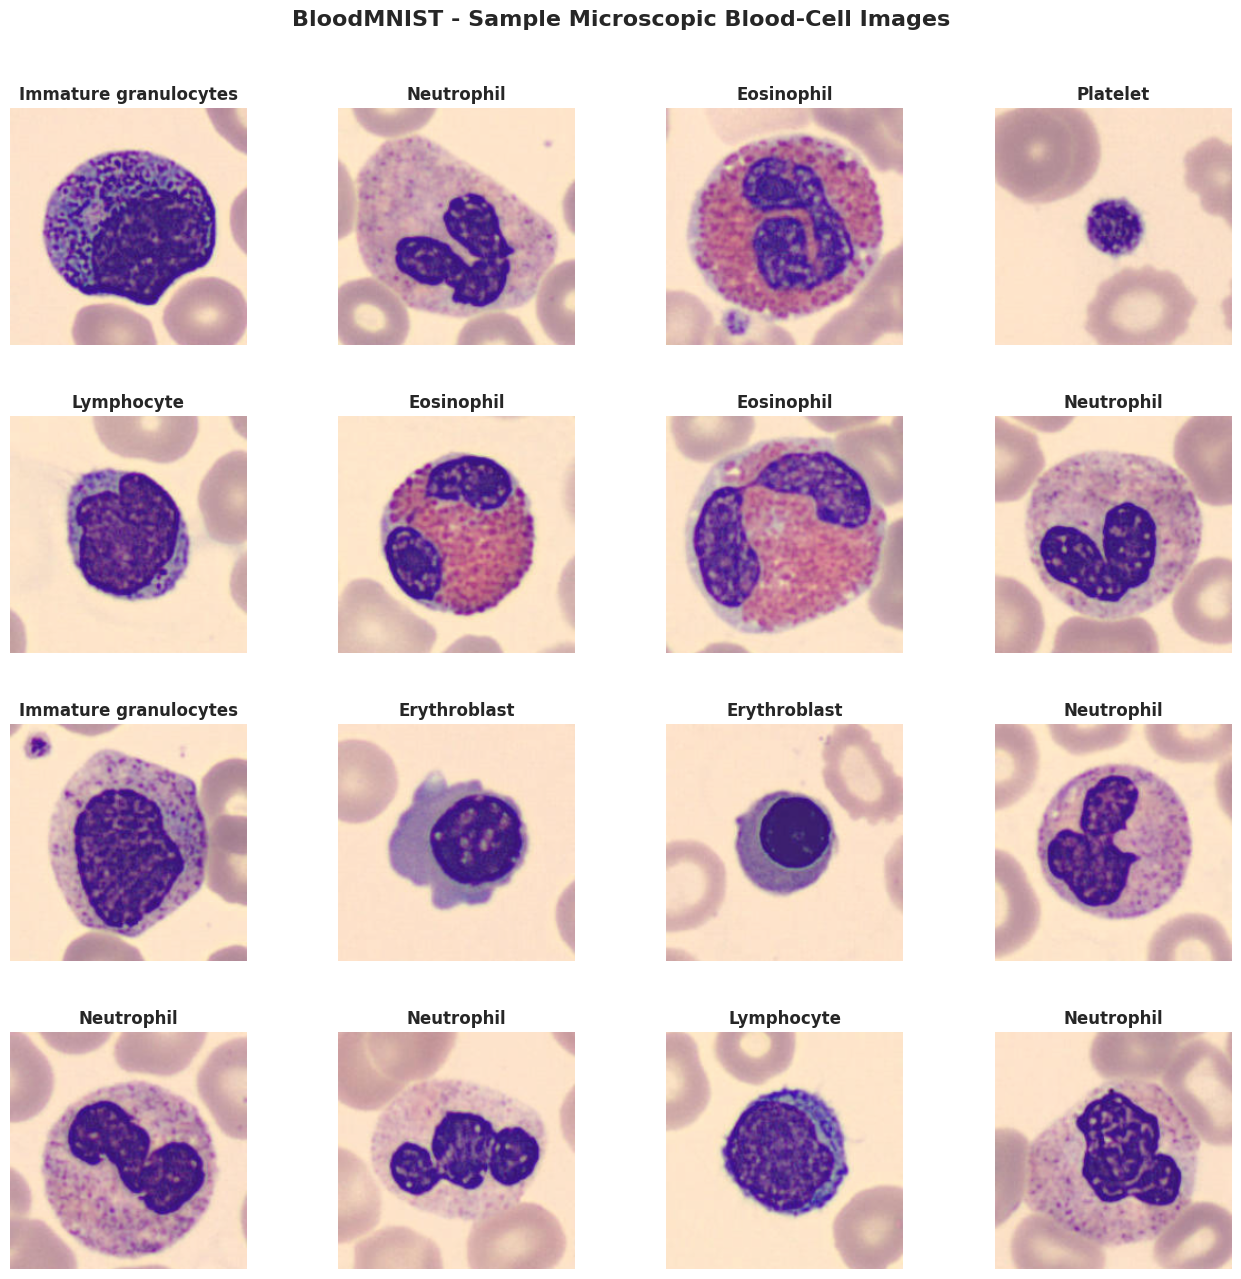

In [ ]:
# Un-augmented copy of the training set, used only for display
display_dataset = DataClass(
    split="train", download=True, size=IMAGE_SIZE,
    as_rgb=True, transform=test_transform
)

def denormalize(tensor):
    img = tensor.permute(1, 2, 0).numpy()
    img = img * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(img, 0, 1)

def show_images(dataset, number=16):
    indices = np.random.choice(len(dataset), number, replace=False)
    fig, axes = plt.subplots(4, 4, figsize=(13, 13))
    axes = axes.flatten()
    for ax, idx in zip(axes, indices):
        image, label = dataset[idx]
        ax.imshow(denormalize(image))
        ax.set_title(display_names[int(label[0])], fontsize=12, fontweight="bold")
        ax.axis("off")
    fig.suptitle("BloodMNIST - Sample Microscopic Blood-Cell Images",
                 fontsize=16, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.subplots_adjust(hspace=0.3, wspace=0.15)
    savefig("sample_images.png")
    plt.show()

show_images(display_dataset)

### Cell 10 (corrected) - Training class distribution

,Blood Cell Type,Number of Images
0,Basophil,852
1,Eosinophil,2181
2,Erythroblast,1085
3,Immature granulocytes,2026
4,Lymphocyte,849
5,Monocyte,993
6,Neutrophil,2330
7,Platelet,1643


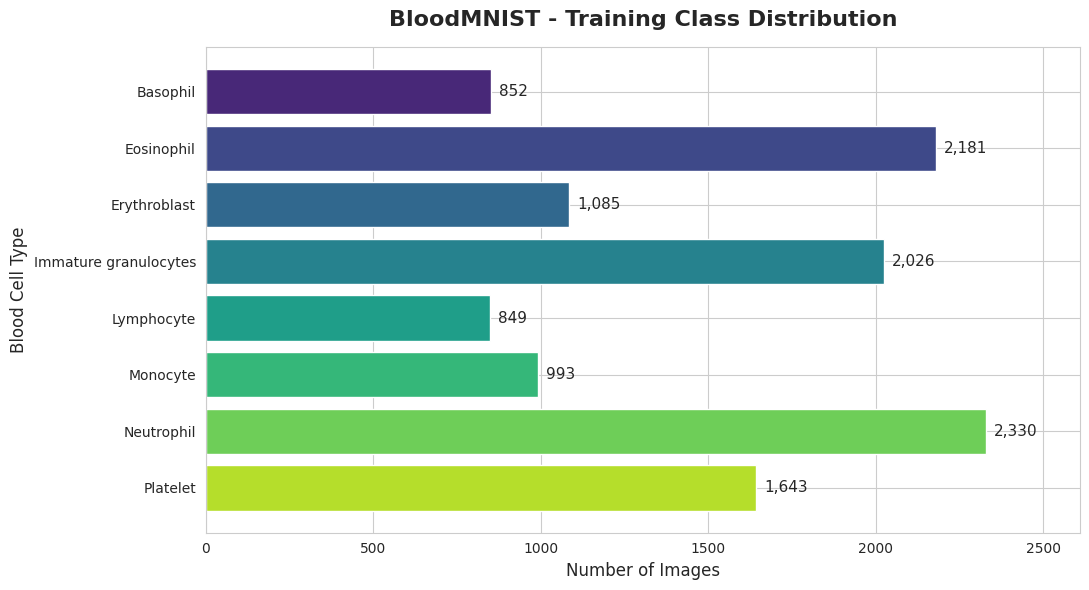

In [ ]:
train_labels = get_labels(train_dataset)
class_counts = np.bincount(train_labels, minlength=NUM_CLASSES)

class_distribution = pd.DataFrame({
    "Blood Cell Type": display_names,
    "Number of Images": class_counts
})
display(class_distribution)

plt.figure(figsize=(11, 6))
bars = plt.barh(display_names, class_counts, color=sns.color_palette("viridis", NUM_CLASSES))
plt.title("BloodMNIST - Training Class Distribution", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Number of Images", fontsize=12)
plt.ylabel("Blood Cell Type", fontsize=12)
plt.gca().invert_yaxis()

for bar in bars:
    width = bar.get_width()
    plt.text(width + max(class_counts) * 0.01, bar.get_y() + bar.get_height() / 2,
             f"{int(width):,}", va="center", fontsize=11)

plt.xlim(0, max(class_counts) * 1.12)
plt.tight_layout()
savefig("class_distribution_train.png")
plt.show()

### Cell 11 (corrected) - Training / validation / testing distribution

,Blood Cell Type,Training,Validation,Testing
0,Basophil,852,122,244
1,Eosinophil,2181,312,624
2,Erythroblast,1085,155,311
3,Immature granulocytes,2026,290,579
4,Lymphocyte,849,122,243
5,Monocyte,993,143,284
6,Neutrophil,2330,333,666
7,Platelet,1643,235,470


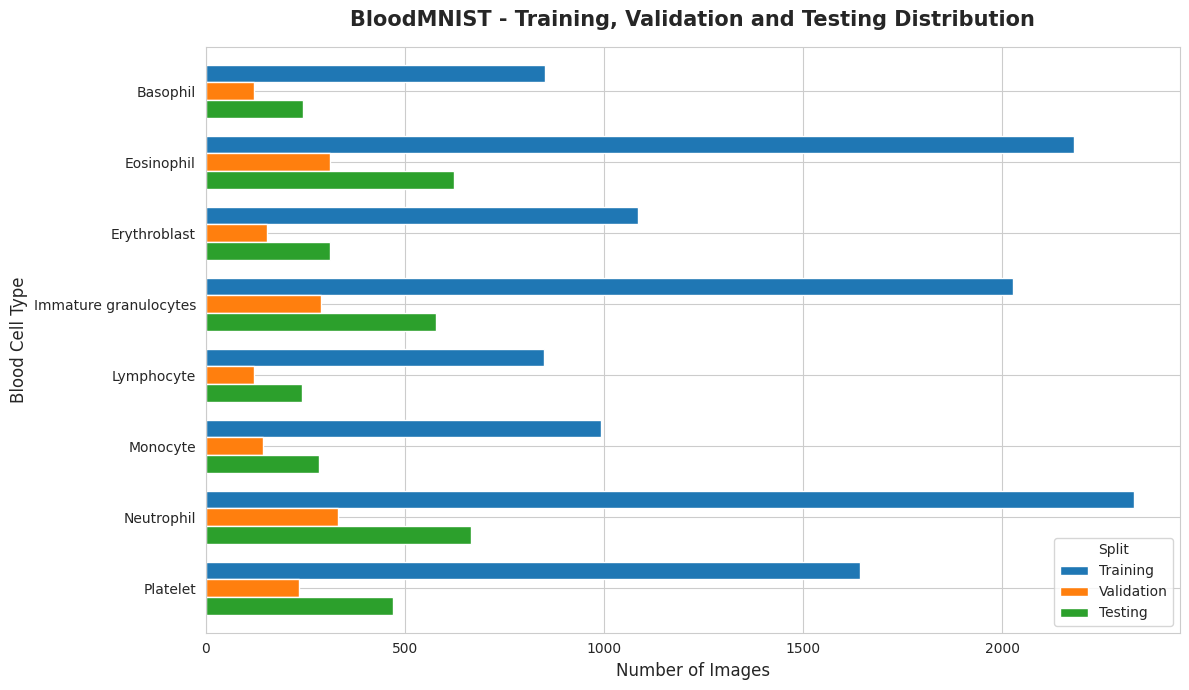

In [ ]:
val_labels = get_labels(val_dataset)
test_labels = get_labels(test_dataset)

split_counts = pd.DataFrame({
    "Blood Cell Type": display_names,
    "Training": np.bincount(train_labels, minlength=NUM_CLASSES),
    "Validation": np.bincount(val_labels, minlength=NUM_CLASSES),
    "Testing": np.bincount(test_labels, minlength=NUM_CLASSES),
})
display(split_counts)
split_counts.to_csv(os.path.join(RES_DIR, "split_class_counts.csv"), index=False)

plot_data = split_counts.set_index("Blood Cell Type")
ax = plot_data.plot(kind="barh", figsize=(12, 7), width=0.75)
ax.set_title("BloodMNIST - Training, Validation and Testing Distribution",
             fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("Number of Images", fontsize=12)
ax.set_ylabel("Blood Cell Type", fontsize=12)
ax.invert_yaxis()
ax.legend(title="Split")
plt.tight_layout()
savefig("class_distribution_splits.png")
plt.show()

## 5. Class weights and data loaders

In [ ]:
# Inverse-frequency class weights computed from the TRAINING labels only
class_weights = len(train_labels) / (NUM_CLASSES * class_counts)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
print(pd.DataFrame({"Class": display_names, "Weight": np.round(class_weights, 3)}))

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
}
train_loader = DataLoader(train_dataset, shuffle=True,  **loader_kwargs)
val_loader   = DataLoader(val_dataset,   shuffle=False, **loader_kwargs)
test_loader  = DataLoader(test_dataset,  shuffle=False, **loader_kwargs)

x, y = next(iter(train_loader))
print("Batch images:", tuple(x.shape), "| Batch labels:", tuple(y.shape))

                   Class  Weight
0               Basophil   1.755
1             Eosinophil   0.685
2           Erythroblast   1.378
3  Immature granulocytes   0.738
4             Lymphocyte   1.761
5               Monocyte   1.505
6             Neutrophil   0.642
7               Platelet   0.910
Batch images: (32, 3, 224, 224) | Batch labels: (32, 1)


## 6. Models (ImageNet-pretrained, final layer replaced with 8 outputs)

In [ ]:
MODEL_NAMES = ["ResNet-18", "DenseNet-121", "EfficientNet-B0"]

def build_model(name):
    if name == "ResNet-18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    elif name == "DenseNet-121":
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        m.classifier = nn.Linear(m.classifier.in_features, NUM_CLASSES)
    elif name == "EfficientNet-B0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
    else:
        raise ValueError(name)
    return m.to(DEVICE)

param_rows = []
for n in MODEL_NAMES:
    m = build_model(n)
    param_rows.append({"Model": n, "Parameters (millions)": round(sum(p.numel() for p in m.parameters()) / 1e6, 2)})
    del m
display(pd.DataFrame(param_rows))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 37.4MB/s]


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:01<00:00, 21.7MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 123MB/s]


,Model,Parameters (millions)
0,ResNet-18,11.18
1,DenseNet-121,6.96
2,EfficientNet-B0,4.02


## 7. Training and evaluation functions

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, n = 0.0, 0
    preds_all, labels_all = [], []

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.squeeze(1).long().to(DEVICE, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                outputs = model(images)
                loss = criterion(outputs, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item() * images.size(0)
            n += images.size(0)
            preds_all.append(outputs.argmax(1).detach().cpu().numpy())
            labels_all.append(labels.cpu().numpy())

    preds_all = np.concatenate(preds_all)
    labels_all = np.concatenate(labels_all)
    return {
        "loss": total_loss / n,
        "acc": accuracy_score(labels_all, preds_all),
        "macro_f1": f1_score(labels_all, preds_all, average="macro", zero_division=0),
    }

def train_model(name):
    set_seed()
    model = build_model(name)
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    tag = name.replace(" ", "_")
    ckpt_path = os.path.join(CKPT_DIR, tag + ".pth")        # best model (by validation macro-F1)
    last_path = os.path.join(CKPT_DIR, tag + "_last.pth")   # full training state, for resuming

    history, best_f1, best_epoch, no_improve = [], -1.0, 0, 0
    start_epoch, prior_time, finished = 1, 0.0, False

    if RESUME and os.path.exists(last_path):
        st = torch.load(last_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(st["model"])
        optimizer.load_state_dict(st["optimizer"])
        scheduler.load_state_dict(st["scheduler"])
        scaler.load_state_dict(st["scaler"])
        history, best_f1, best_epoch = st["history"], st["best_f1"], st["best_epoch"]
        no_improve, start_epoch = st["no_improve"], st["epoch"] + 1
        prior_time, finished = st["elapsed"], st["finished"]
        print(f"[{name}] Resuming from epoch {st['epoch']} (finished={finished}).")

    start = time.time()

    def save_last(epoch, done_flag):
        torch.save({
            "model": model.state_dict(), "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
            "history": history, "best_f1": best_f1, "best_epoch": best_epoch,
            "no_improve": no_improve, "epoch": epoch, "finished": done_flag,
            "elapsed": prior_time + time.time() - start,
        }, last_path)

    for epoch in range(start_epoch, EPOCHS + 1):
        if finished:
            break
        t0 = time.time()
        tr = run_epoch(model, train_loader, criterion, optimizer, scaler)
        va = run_epoch(model, val_loader, criterion)
        scheduler.step(va["loss"])
        lr_now = optimizer.param_groups[0]["lr"]

        history.append({
            "epoch": epoch,
            "train_loss": float(tr["loss"]), "train_acc": float(tr["acc"]),
            "val_loss": float(va["loss"]), "val_acc": float(va["acc"]),
            "val_macro_f1": float(va["macro_f1"]),
            "lr": float(lr_now), "epoch_time_s": time.time() - t0,
        })
        print(f"[{name}] Epoch {epoch:02d}/{EPOCHS} | "
              f"train loss {tr['loss']:.4f} acc {tr['acc']:.4f} | "
              f"val loss {va['loss']:.4f} acc {va['acc']:.4f} macroF1 {va['macro_f1']:.4f} | "
              f"lr {lr_now:.2e} | {time.time() - t0:.0f}s")

        if va["macro_f1"] > best_f1:
            best_f1, best_epoch, no_improve = float(va["macro_f1"]), epoch, 0
            torch.save({"model_name": name, "state_dict": model.state_dict(),
                        "epoch": epoch, "val_macro_f1": best_f1}, ckpt_path)
        else:
            no_improve += 1

        stop = no_improve >= EARLY_STOP_PATIENCE
        if stop:
            print(f"[{name}] Early stopping at epoch {epoch} (best epoch {best_epoch}).")
        finished = stop or epoch == EPOCHS
        save_last(epoch, finished)
        if stop:
            break

    train_time = prior_time + time.time() - start
    hist_df = pd.DataFrame(history)
    hist_df.to_csv(os.path.join(RES_DIR, f"history_{tag}.csv"), index=False)
    del model, optimizer
    return hist_df, train_time, best_epoch, ckpt_path

@torch.no_grad()
def predict_probs(model, loader):
    model.eval()
    probs, labels = [], []
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    for images, y in loader:
        images = images.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            out = model(images)
        probs.append(torch.softmax(out.float(), dim=1).cpu().numpy())
        labels.append(y.squeeze(1).numpy())
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return np.concatenate(probs), np.concatenate(labels).astype(int), time.time() - t0

def compute_metrics(y_true, probs):
    y_pred = probs.argmax(1)
    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    tp = np.diag(cm)
    fp = cm.sum(0) - tp
    fn = cm.sum(1) - tp
    tn = cm.sum() - (tp + fp + fn)
    onehot = np.eye(NUM_CLASSES)[y_true]
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Specificity": float(np.mean(tn / (tn + fp))),
        "ROC-AUC": roc_auc_score(onehot, probs, average="macro"),
        "Probability RMSE": float(np.sqrt(np.mean((probs - onehot) ** 2))),
        "Brier Score": float(np.mean(np.sum((probs - onehot) ** 2, axis=1))),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }

results = {}

def run_experiment(name):
    hist, train_time, best_epoch, ckpt_path = train_model(name)
    model = build_model(name)
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE, weights_only=False)["state_dict"])

    val_probs, val_y, _ = predict_probs(model, val_loader)
    test_probs, test_y, inf_time = predict_probs(model, test_loader)

    results[name] = {
        "history": hist, "train_time_s": train_time,
        "epochs_run": len(hist), "best_epoch": best_epoch,
        "val_probs": val_probs, "val_y": val_y,
        "test_probs": test_probs, "test_y": test_y,
        "inference_time_s": inf_time,
        "val_metrics": compute_metrics(val_y, val_probs),
        "test_metrics": compute_metrics(test_y, test_probs),
        "ckpt_path": ckpt_path,
    }
    r = results[name]
    print(f"\n[{name}] done | epochs run {r['epochs_run']} | best epoch {best_epoch} | "
          f"train time {train_time / 60:.1f} min | "
          f"val macro-F1 {r['val_metrics']['Macro F1']:.4f} | test accuracy {r['test_metrics']['Accuracy']:.4f}")
    del model
    torch.cuda.empty_cache()

## 8. Train the three models
Run each cell in turn. A resume file is saved after every epoch, so if Colab disconnects you can re-run the same cell and it continues (set `USE_GOOGLE_DRIVE = True` in the config cell so the files survive a disconnect).

### Model 1 - ResNet-18

In [ ]:
run_experiment("ResNet-18")

[ResNet-18] Epoch 01/20 | train loss 0.1744 acc 0.9455 | val loss 0.0352 acc 0.9877 macroF1 0.9886 | lr 1.00e-04 | 48s
[ResNet-18] Epoch 02/20 | train loss 0.0682 acc 0.9758 | val loss 0.0419 acc 0.9866 macroF1 0.9856 | lr 1.00e-04 | 44s
[ResNet-18] Epoch 03/20 | train loss 0.0548 acc 0.9810 | val loss 0.0216 acc 0.9924 macroF1 0.9929 | lr 1.00e-04 | 47s
[ResNet-18] Epoch 04/20 | train loss 0.0402 acc 0.9860 | val loss 0.0633 acc 0.9725 macroF1 0.9712 | lr 1.00e-04 | 48s
[ResNet-18] Epoch 05/20 | train loss 0.0417 acc 0.9845 | val loss 0.0388 acc 0.9819 macroF1 0.9827 | lr 1.00e-04 | 46s
[ResNet-18] Epoch 06/20 | train loss 0.0334 acc 0.9887 | val loss 0.0364 acc 0.9877 macroF1 0.9900 | lr 5.00e-05 | 47s
[ResNet-18] Epoch 07/20 | train loss 0.0226 acc 0.9907 | val loss 0.0206 acc 0.9930 macroF1 0.9944 | lr 5.00e-05 | 48s
[ResNet-18] Epoch 08/20 | train loss 0.0203 acc 0.9919 | val loss 0.0297 acc 0.9877 macroF1 0.9895 | lr 5.00e-05 | 46s
[ResNet-18] Epoch 09/20 | train loss 0.0201 acc 

### Model 2 - DenseNet-121

In [ ]:
run_experiment("DenseNet-121")

[DenseNet-121] Epoch 01/20 | train loss 0.2147 acc 0.9425 | val loss 0.0869 acc 0.9743 macroF1 0.9683 | lr 1.00e-04 | 105s
[DenseNet-121] Epoch 02/20 | train loss 0.0617 acc 0.9802 | val loss 0.0373 acc 0.9854 macroF1 0.9861 | lr 1.00e-04 | 103s
[DenseNet-121] Epoch 03/20 | train loss 0.0429 acc 0.9850 | val loss 0.0236 acc 0.9918 macroF1 0.9924 | lr 1.00e-04 | 102s
[DenseNet-121] Epoch 04/20 | train loss 0.0389 acc 0.9864 | val loss 0.0375 acc 0.9836 macroF1 0.9866 | lr 1.00e-04 | 105s
[DenseNet-121] Epoch 05/20 | train loss 0.0352 acc 0.9875 | val loss 0.0215 acc 0.9918 macroF1 0.9925 | lr 1.00e-04 | 105s
[DenseNet-121] Epoch 06/20 | train loss 0.0272 acc 0.9910 | val loss 0.0312 acc 0.9901 macroF1 0.9910 | lr 1.00e-04 | 104s
[DenseNet-121] Epoch 07/20 | train loss 0.0268 acc 0.9902 | val loss 0.0192 acc 0.9936 macroF1 0.9946 | lr 1.00e-04 | 106s
[DenseNet-121] Epoch 08/20 | train loss 0.0215 acc 0.9911 | val loss 0.0391 acc 0.9836 macroF1 0.9854 | lr 1.00e-04 | 107s
[DenseNet-121] E

### Model 3 - EfficientNet-B0

In [ ]:
run_experiment("EfficientNet-B0")

[EfficientNet-B0] Epoch 01/20 | train loss 0.3595 acc 0.9132 | val loss 0.0585 acc 0.9720 macroF1 0.9701 | lr 1.00e-04 | 72s
[EfficientNet-B0] Epoch 02/20 | train loss 0.0847 acc 0.9710 | val loss 0.0289 acc 0.9895 macroF1 0.9890 | lr 1.00e-04 | 68s
[EfficientNet-B0] Epoch 03/20 | train loss 0.0509 acc 0.9822 | val loss 0.0259 acc 0.9907 macroF1 0.9920 | lr 1.00e-04 | 69s
[EfficientNet-B0] Epoch 04/20 | train loss 0.0440 acc 0.9848 | val loss 0.0273 acc 0.9907 macroF1 0.9916 | lr 1.00e-04 | 71s
[EfficientNet-B0] Epoch 05/20 | train loss 0.0413 acc 0.9844 | val loss 0.0192 acc 0.9942 macroF1 0.9944 | lr 1.00e-04 | 69s
[EfficientNet-B0] Epoch 06/20 | train loss 0.0342 acc 0.9873 | val loss 0.0267 acc 0.9860 macroF1 0.9886 | lr 1.00e-04 | 66s
[EfficientNet-B0] Epoch 07/20 | train loss 0.0257 acc 0.9910 | val loss 0.0192 acc 0.9936 macroF1 0.9943 | lr 1.00e-04 | 67s
[EfficientNet-B0] Epoch 08/20 | train loss 0.0222 acc 0.9915 | val loss 0.0166 acc 0.9947 macroF1 0.9949 | lr 1.00e-04 | 68s


## 9. Accuracy and loss curves

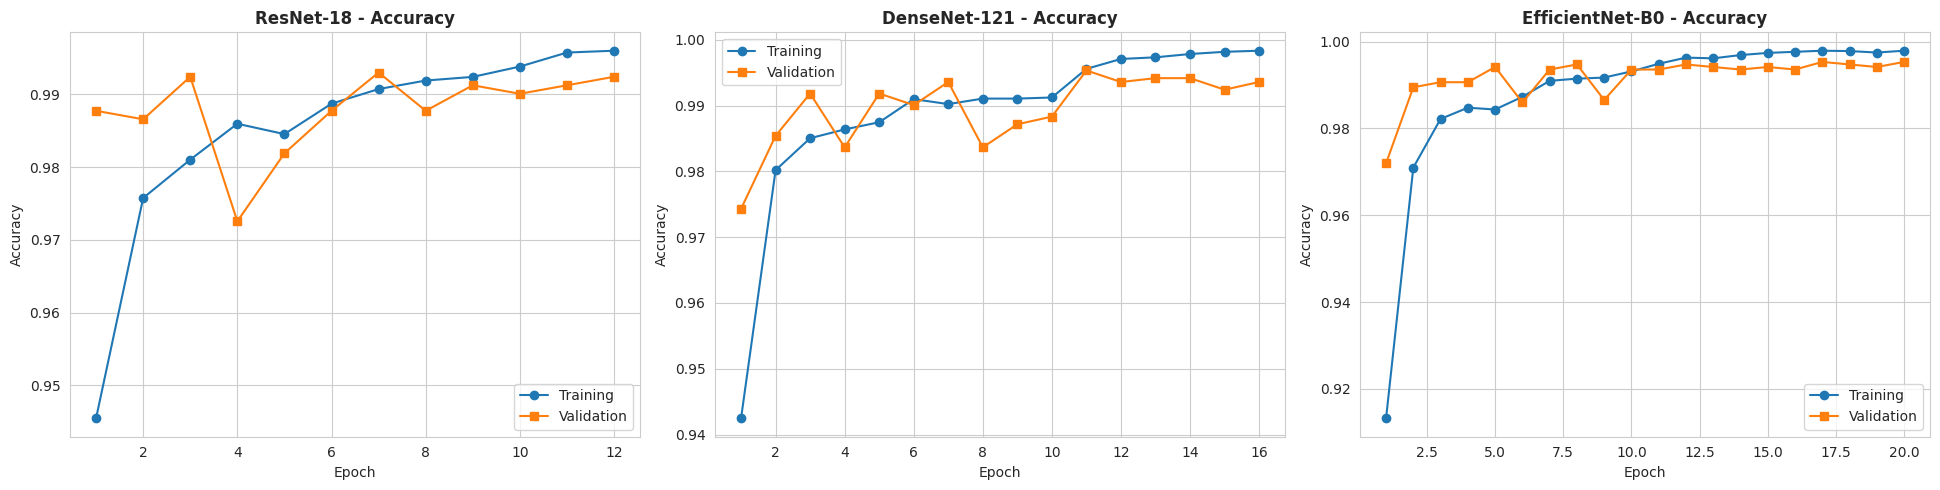

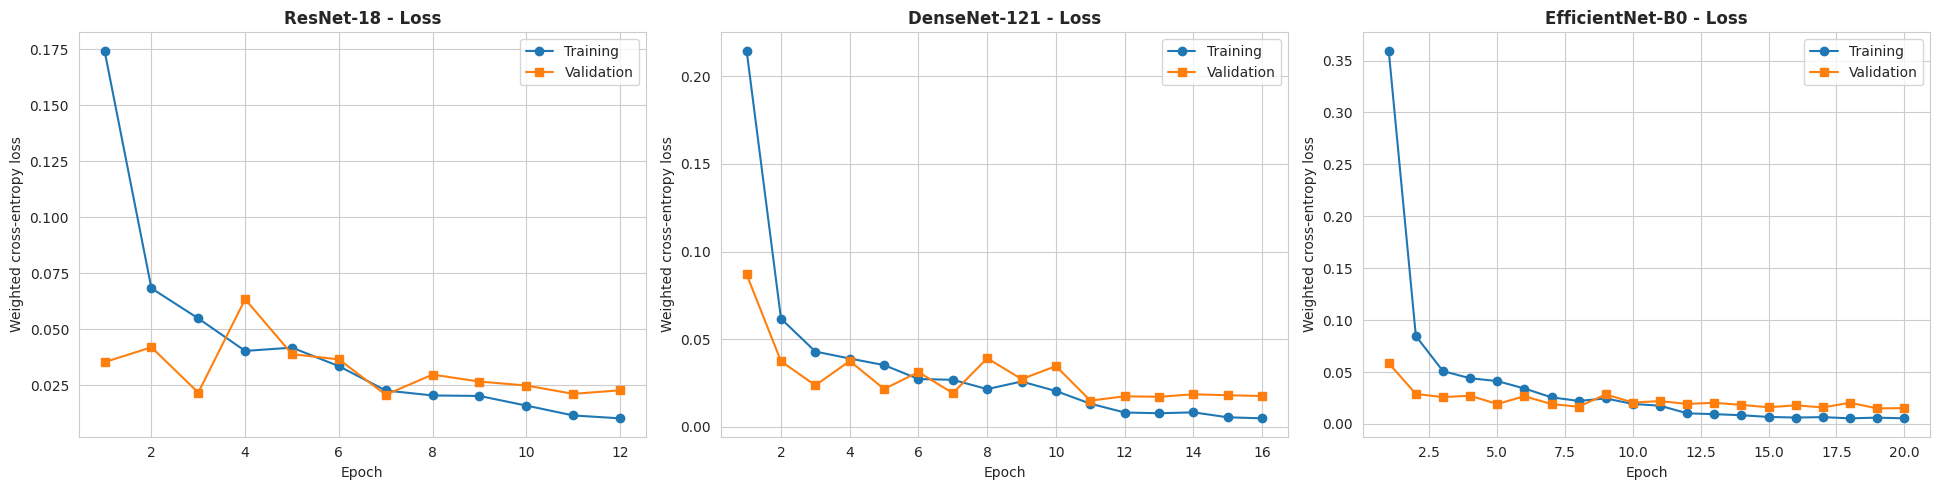

In [ ]:
assert len(results) == len(MODEL_NAMES), (
    "Please complete training all three models before comparison."
)

done = [n for n in MODEL_NAMES if n in results]

fig, axes = plt.subplots(1, len(done), figsize=(6.5 * len(done), 5), squeeze=False)
for ax, n in zip(axes[0], done):
    h = results[n]["history"]
    ax.plot(h["epoch"], h["train_acc"], marker="o", label="Training")
    ax.plot(h["epoch"], h["val_acc"], marker="s", label="Validation")
    ax.set_title(f"{n} - Accuracy", fontweight="bold")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy"); ax.legend()
plt.tight_layout(); savefig("accuracy_curves.png"); plt.show()

fig, axes = plt.subplots(1, len(done), figsize=(6.5 * len(done), 5), squeeze=False)
for ax, n in zip(axes[0], done):
    h = results[n]["history"]
    ax.plot(h["epoch"], h["train_loss"], marker="o", label="Training")
    ax.plot(h["epoch"], h["val_loss"], marker="s", label="Validation")
    ax.set_title(f"{n} - Loss", fontweight="bold")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Weighted cross-entropy loss"); ax.legend()
plt.tight_layout(); savefig("loss_curves.png"); plt.show()

## 10. Confusion matrices (test set)

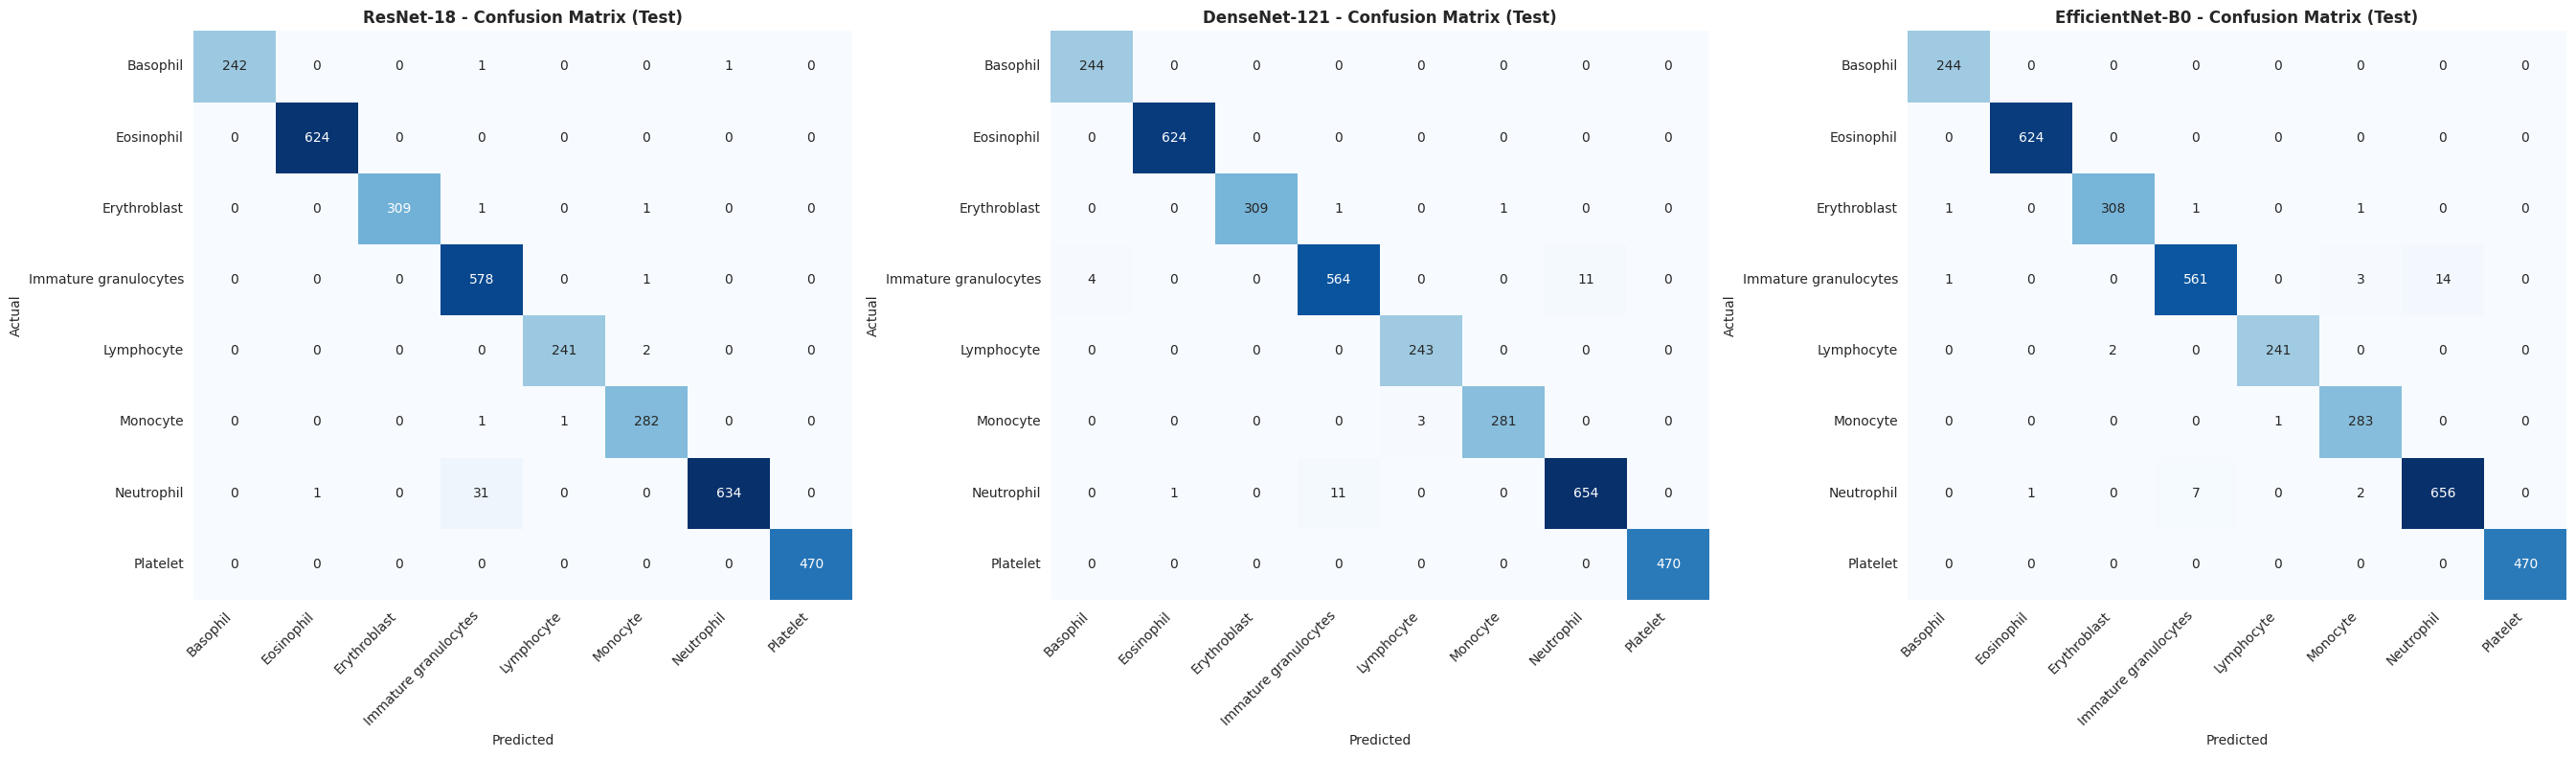

In [ ]:
fig, axes = plt.subplots(1, len(done), figsize=(9 * len(done), 8), squeeze=False)
for ax, n in zip(axes[0], done):
    r = results[n]
    cm = confusion_matrix(r["test_y"], r["test_probs"].argmax(1), labels=list(range(NUM_CLASSES)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=display_names, yticklabels=display_names)
    ax.set_title(f"{n} - Confusion Matrix (Test)", fontweight="bold")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.tick_params(axis="x", rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout(); savefig("confusion_matrices.png"); plt.show()

## 11. ROC curves and precision-recall curves (test set)

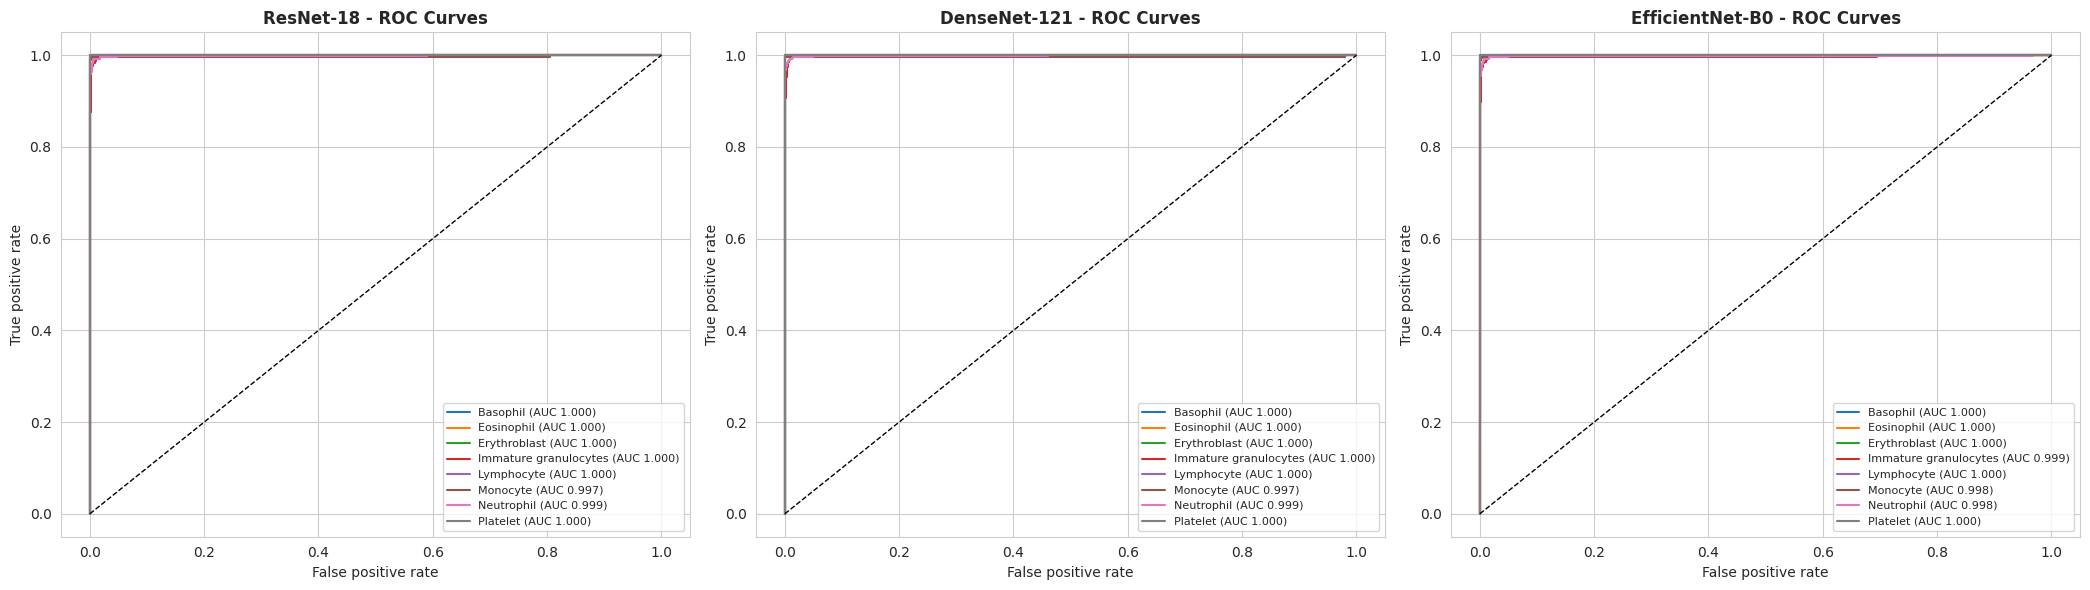

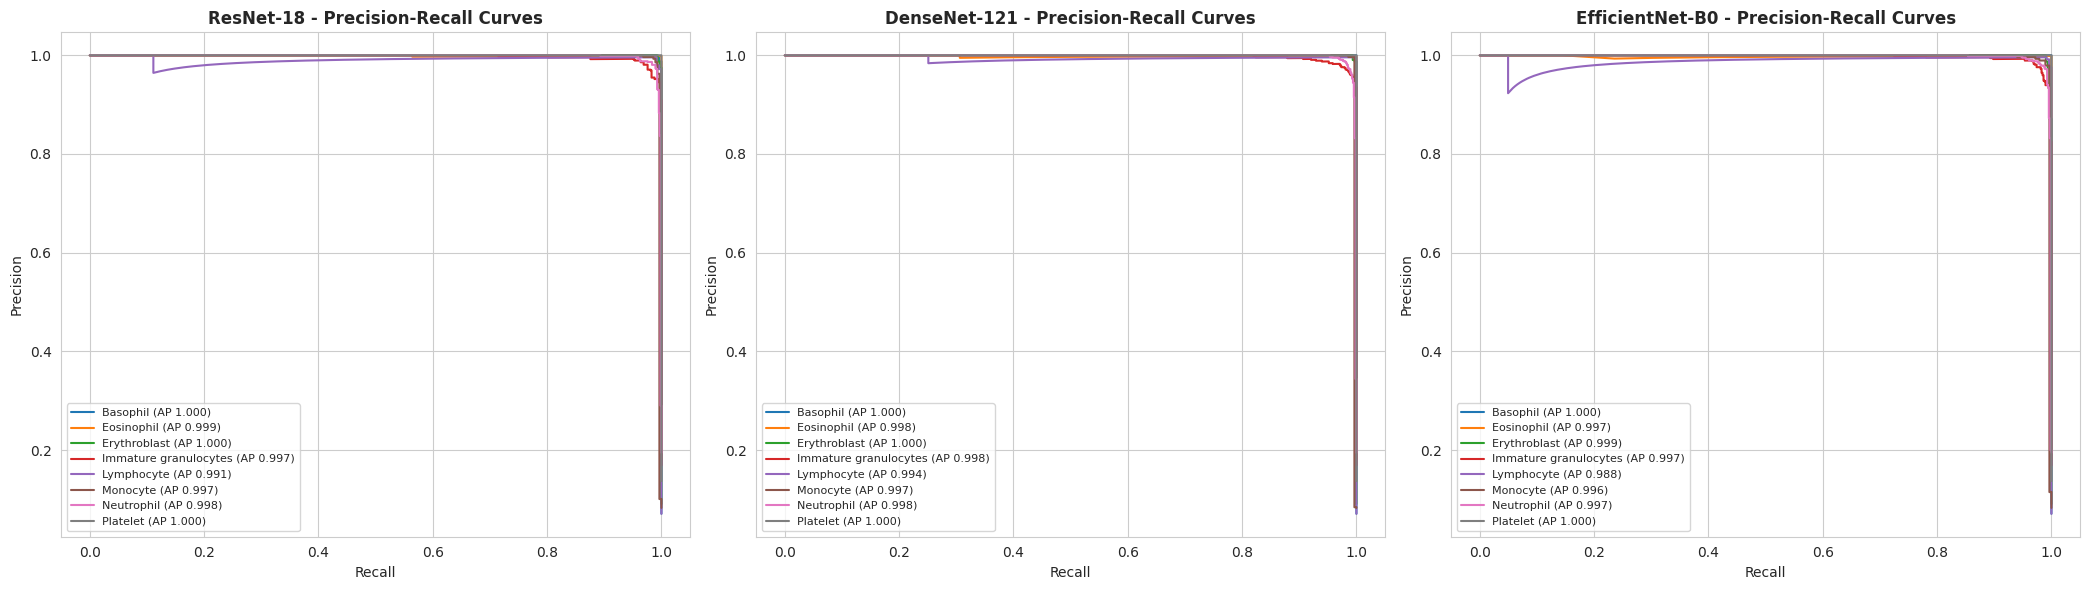

In [ ]:
colors = sns.color_palette("tab10", NUM_CLASSES)

fig, axes = plt.subplots(1, len(done), figsize=(7 * len(done), 6), squeeze=False)
for ax, n in zip(axes[0], done):
    r = results[n]
    onehot = label_binarize(r["test_y"], classes=list(range(NUM_CLASSES)))
    for c in range(NUM_CLASSES):
        fpr, tpr, _ = roc_curve(onehot[:, c], r["test_probs"][:, c])
        ax.plot(fpr, tpr, color=colors[c], label=f"{display_names[c]} (AUC {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set_title(f"{n} - ROC Curves", fontweight="bold")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); savefig("roc_curves.png"); plt.show()

fig, axes = plt.subplots(1, len(done), figsize=(7 * len(done), 6), squeeze=False)
for ax, n in zip(axes[0], done):
    r = results[n]
    onehot = label_binarize(r["test_y"], classes=list(range(NUM_CLASSES)))
    for c in range(NUM_CLASSES):
        p, rc, _ = precision_recall_curve(onehot[:, c], r["test_probs"][:, c])
        ap = average_precision_score(onehot[:, c], r["test_probs"][:, c])
        ax.plot(rc, p, color=colors[c], label=f"{display_names[c]} (AP {ap:.3f})")
    ax.set_title(f"{n} - Precision-Recall Curves", fontweight="bold")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); savefig("precision_recall_curves.png"); plt.show()

## 12. Final comparison table (filled from the actual run)

In [ ]:
assert len(results) == len(MODEL_NAMES), (
    "Please complete training all three models before comparison."
)

metric_order = ["Accuracy", "Precision", "Recall", "Macro F1", "Weighted F1", "Specificity",
                "ROC-AUC", "Probability RMSE", "Brier Score", "Cohen's Kappa", "MCC"]

test_table = pd.DataFrame({n: results[n]["test_metrics"] for n in done}).loc[metric_order]
test_table.loc["Training time (min)"] = [results[n]["train_time_s"] / 60 for n in done]
test_table.loc["Inference time, test set (s)"] = [results[n]["inference_time_s"] for n in done]
test_table.loc["Epochs run"] = [results[n]["epochs_run"] for n in done]
test_table.loc["Best epoch"] = [results[n]["best_epoch"] for n in done]
test_table.to_csv(os.path.join(RES_DIR, "test_metrics_comparison.csv"))

val_table = pd.DataFrame({n: results[n]["val_metrics"] for n in done}).loc[metric_order]
val_table.to_csv(os.path.join(RES_DIR, "validation_metrics_comparison.csv"))

print("TEST METRICS")
display(test_table.round(4))
print("VALIDATION METRICS")
display(val_table.round(4))

TEST METRICS


,ResNet-18,DenseNet-121,EfficientNet-B0
Accuracy,0.9880,0.9906,0.9901
Precision,0.9904,0.9911,0.9905
Recall,0.9900,0.9924,0.9916
Macro F1,0.9900,0.9917,0.9910
Weighted F1,0.9880,0.9906,0.9900
Specificity,0.9982,0.9986,0.9985
ROC-AUC,0.9994,0.9993,0.9993
Probability RMSE,0.0491,0.0430,0.0455
Brier Score,0.0193,0.0148,0.0165
Cohen's Kappa,0.9860,0.9891,0.9884


VALIDATION METRICS


,ResNet-18,DenseNet-121,EfficientNet-B0
Accuracy,0.9930,0.9953,0.9953
Precision,0.9936,0.9953,0.9961
Recall,0.9953,0.9963,0.9966
Macro F1,0.9944,0.9958,0.9963
Weighted F1,0.9930,0.9953,0.9953
Specificity,0.9990,0.9993,0.9993
ROC-AUC,0.9998,1.0000,1.0000
Probability RMSE,0.0384,0.0328,0.0327
Brier Score,0.0118,0.0086,0.0085
Cohen's Kappa,0.9918,0.9945,0.9945


## 13. Model comparison charts

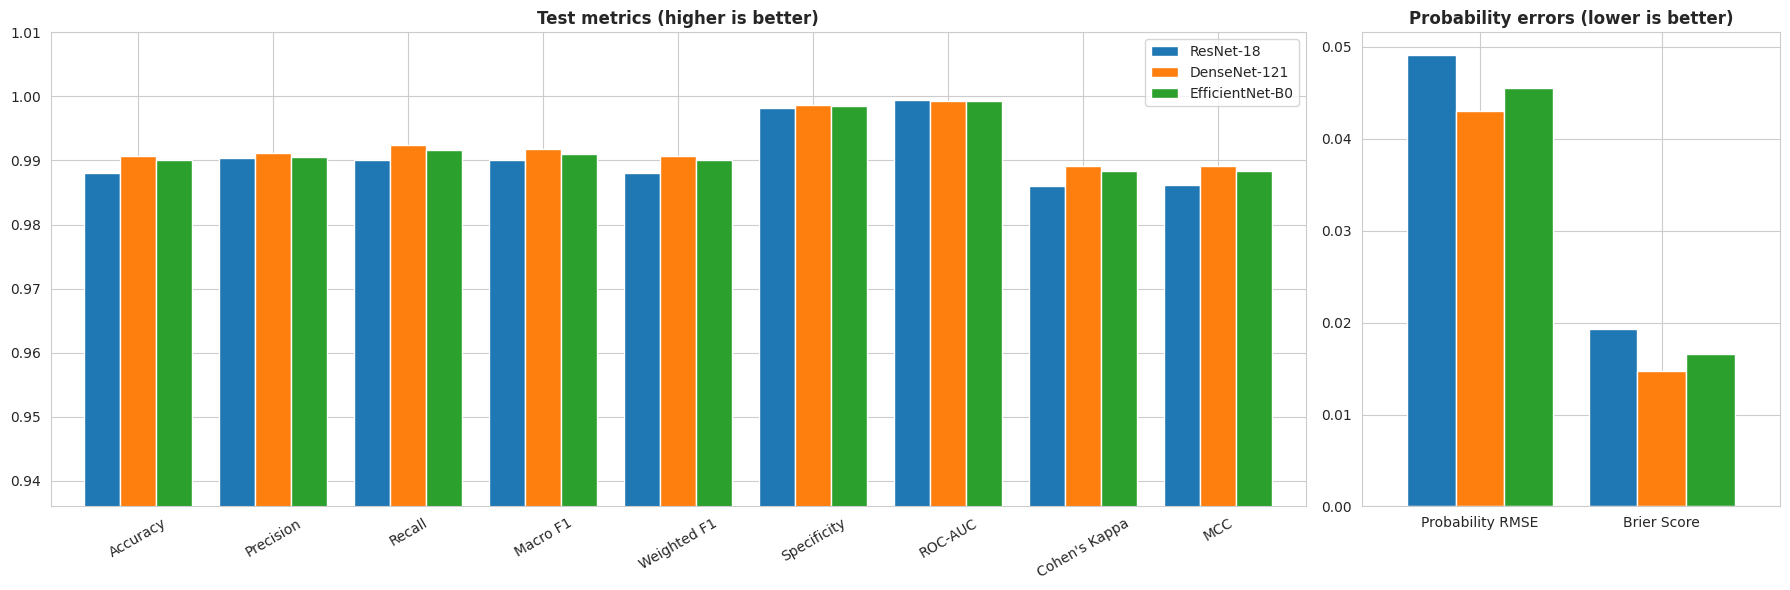

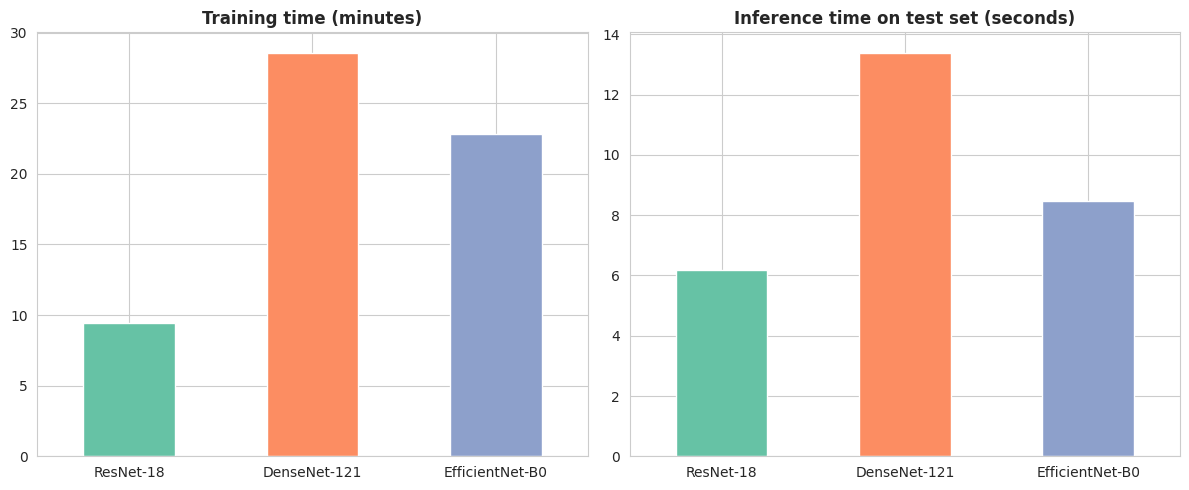

In [ ]:
higher = ["Accuracy", "Precision", "Recall", "Macro F1", "Weighted F1", "Specificity", "ROC-AUC", "Cohen's Kappa", "MCC"]
lower = ["Probability RMSE", "Brier Score"]

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [3, 1]})
test_table.loc[higher].plot(kind="bar", ax=axes[0], width=0.8)
axes[0].set_title("Test metrics (higher is better)", fontweight="bold")
axes[0].set_ylim(max(0, test_table.loc[higher].values.min() - 0.05), 1.01)
axes[0].tick_params(axis="x", rotation=30)
test_table.loc[lower].plot(kind="bar", ax=axes[1], width=0.8, legend=False)
axes[1].set_title("Probability errors (lower is better)", fontweight="bold")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); savefig("model_comparison_metrics.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
tt = pd.Series({n: results[n]["train_time_s"] / 60 for n in done})
it = pd.Series({n: results[n]["inference_time_s"] for n in done})
tt.plot(kind="bar", ax=axes[0], color=sns.color_palette("Set2")[:len(done)])
axes[0].set_title("Training time (minutes)", fontweight="bold"); axes[0].tick_params(axis="x", rotation=0)
it.plot(kind="bar", ax=axes[1], color=sns.color_palette("Set2")[:len(done)])
axes[1].set_title("Inference time on test set (seconds)", fontweight="bold"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); savefig("time_comparison.png"); plt.show()

## 14. Class-wise F1 and classification reports

===== ResNet-18 =====
                       precision    recall  f1-score   support

             Basophil     1.0000    0.9918    0.9959       244
           Eosinophil     0.9984    1.0000    0.9992       624
         Erythroblast     1.0000    0.9936    0.9968       311
Immature granulocytes     0.9444    0.9983    0.9706       579
           Lymphocyte     0.9959    0.9918    0.9938       243
             Monocyte     0.9860    0.9930    0.9895       284
           Neutrophil     0.9984    0.9520    0.9746       666
             Platelet     1.0000    1.0000    1.0000       470

             accuracy                         0.9880      3421
            macro avg     0.9904    0.9900    0.9900      3421
         weighted avg     0.9885    0.9880    0.9880      3421

===== DenseNet-121 =====
                       precision    recall  f1-score   support

             Basophil     0.9839    1.0000    0.9919       244
           Eosinophil     0.9984    1.0000    0.9992       624
    

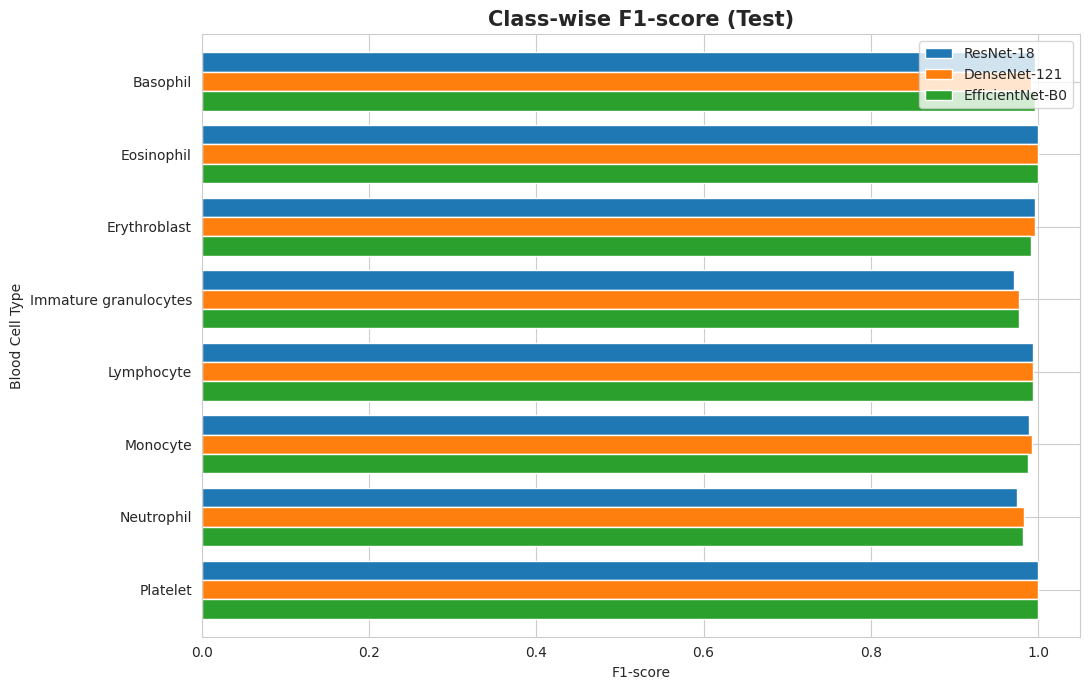

In [ ]:
f1_rows = {}
for n in done:
    r = results[n]
    y_pred = r["test_probs"].argmax(1)
    _, _, f1c, _ = precision_recall_fscore_support(
        r["test_y"], y_pred, labels=list(range(NUM_CLASSES)), zero_division=0)
    f1_rows[n] = f1c

    report = classification_report(r["test_y"], y_pred, target_names=display_names,
                                   output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(os.path.join(RES_DIR, f"classification_report_{n.replace(' ', '_')}.csv"))
    print(f"===== {n} =====")
    print(classification_report(r["test_y"], y_pred, target_names=display_names, digits=4, zero_division=0))

class_f1 = pd.DataFrame(f1_rows, index=display_names)
class_f1.to_csv(os.path.join(RES_DIR, "classwise_f1.csv"))

ax = class_f1.plot(kind="barh", figsize=(11, 7), width=0.8)
ax.set_title("Class-wise F1-score (Test)", fontsize=15, fontweight="bold")
ax.set_xlabel("F1-score"); ax.set_ylabel("Blood Cell Type")
ax.invert_yaxis()
plt.tight_layout(); savefig("classwise_f1.png"); plt.show()

## 15. Best model selection (highest validation macro-F1)

Best validation macro-F1 and epoch per architecture


,Best validation macro-F1,Best epoch,Epochs run
Model,,,
ResNet-18,0.9944,7.0,12.0
DenseNet-121,0.9958,11.0,16.0
EfficientNet-B0,0.9963,17.0,20.0


,Rank (by validation macro-F1),Validation Macro F1,Test Macro F1,Test Accuracy,Best Epoch
Model,,,,,
EfficientNet-B0,1,0.9963,0.9910,0.9901,17
DenseNet-121,2,0.9958,0.9917,0.9906,11
ResNet-18,3,0.9944,0.9900,0.9880,7


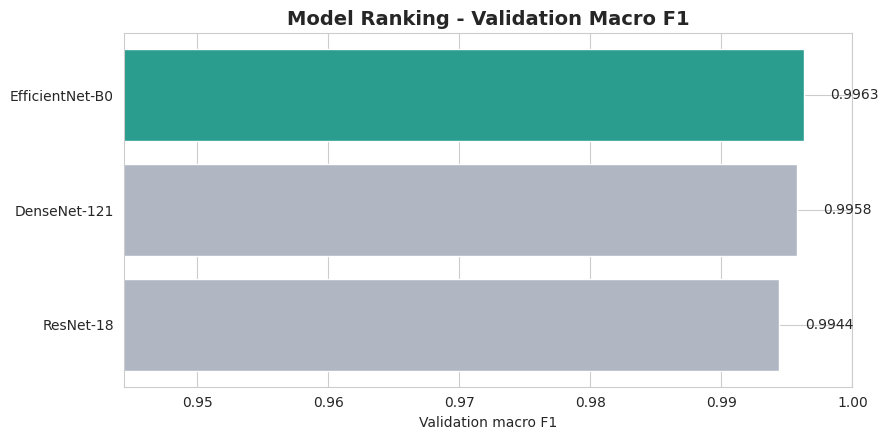

Best model by validation macro-F1: EfficientNet-B0
Its test-set performance:


,Test
Accuracy,0.9901
Precision,0.9905
Recall,0.9916
Macro F1,0.9910
Weighted F1,0.9900
Specificity,0.9985
ROC-AUC,0.9993
Probability RMSE,0.0455
Brier Score,0.0165
Cohen's Kappa,0.9884


Saved: /content/drive/MyDrive/BloodMNIST_outputs/checkpoints/best_model.pth


In [ ]:
val_f1 = pd.Series({n: results[n]["val_metrics"]["Macro F1"] for n in done}).sort_values(ascending=False)
best_name = val_f1.index[0]

best_epoch_table = pd.DataFrame({
    n: {
        "Best validation macro-F1": results[n]["history"]["val_macro_f1"].max(),
        "Best epoch": int(results[n]["history"].loc[results[n]["history"]["val_macro_f1"].idxmax(), "epoch"]),
        "Epochs run": results[n]["epochs_run"],
    } for n in done
}).T
best_epoch_table.index.name = "Model"
best_epoch_table.to_csv(os.path.join(RES_DIR, "best_validation_epoch.csv"))
print("Best validation macro-F1 and epoch per architecture")
display(best_epoch_table.round(4))

ranking = pd.DataFrame({
    "Validation Macro F1": val_f1,
    "Test Macro F1": [results[n]["test_metrics"]["Macro F1"] for n in val_f1.index],
    "Test Accuracy": [results[n]["test_metrics"]["Accuracy"] for n in val_f1.index],
    "Best Epoch": [results[n]["best_epoch"] for n in val_f1.index],
})
ranking.index.name = "Model"
ranking.insert(0, "Rank (by validation macro-F1)", range(1, len(ranking) + 1))
ranking.to_csv(os.path.join(RES_DIR, "model_ranking.csv"))
display(ranking.round(4))

plt.figure(figsize=(9, 4.5))
bar_colors = ["#2a9d8f" if n == best_name else "#b0b7c3" for n in val_f1.index]
bars = plt.barh(val_f1.index, val_f1.values, color=bar_colors)
plt.gca().invert_yaxis()
for b in bars:
    plt.text(b.get_width() + 0.002, b.get_y() + b.get_height() / 2, f"{b.get_width():.4f}", va="center")
plt.xlim(max(0, val_f1.min() - 0.05), min(1.0, val_f1.max() + 0.03))
plt.title("Model Ranking - Validation Macro F1", fontsize=14, fontweight="bold")
plt.xlabel("Validation macro F1")
plt.tight_layout(); savefig("model_ranking.png"); plt.show()

best_path = os.path.join(CKPT_DIR, "best_model.pth")
shutil.copy(results[best_name]["ckpt_path"], best_path)
print(f"Best model by validation macro-F1: {best_name}")
print("Its test-set performance:")
display(pd.Series(results[best_name]["test_metrics"]).round(4).to_frame("Test"))
print("Saved:", best_path)

## 16. Actual vs predicted examples (best model, test set)

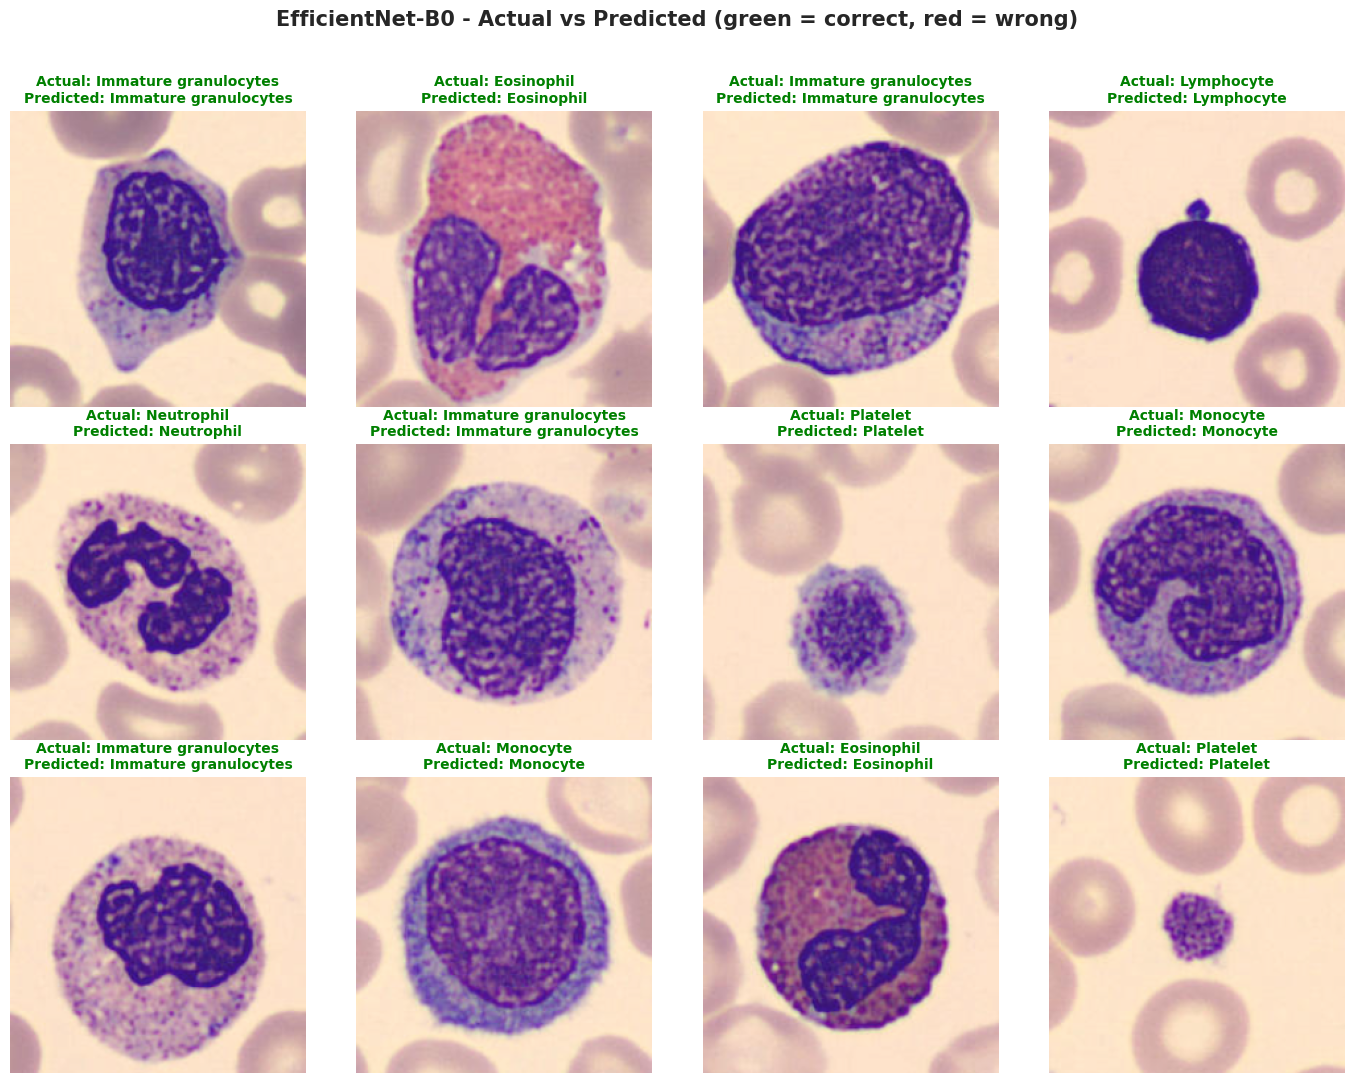

In [ ]:
best_model = build_model(best_name)
best_model.load_state_dict(torch.load(best_path, map_location=DEVICE, weights_only=False)["state_dict"])
best_model.eval()

idx = np.random.RandomState(SEED).choice(len(test_dataset), 12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for ax, i in zip(axes.flatten(), idx):
    image, label = test_dataset[i]
    with torch.no_grad():
        pred = best_model(image.unsqueeze(0).to(DEVICE)).argmax(1).item()
    true = int(label[0])
    ax.imshow(denormalize(image)); ax.axis("off")
    ax.set_title(f"Actual: {display_names[true]}\nPredicted: {display_names[pred]}", fontsize=10,
                 color="green" if pred == true else "red", fontweight="bold")
fig.suptitle(f"{best_name} - Actual vs Predicted (green = correct, red = wrong)", fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96]); savefig("actual_vs_predicted.png"); plt.show()

## 17. Save and download everything

In [ ]:
for n in done:
    pd.DataFrame(results[n]["test_probs"], columns=display_names).assign(
        true_label=[display_names[i] for i in results[n]["test_y"]]
    ).to_csv(os.path.join(RES_DIR, f"test_predictions_{n.replace(' ', '_')}.csv"), index=False)

shutil.make_archive("blood_cell_project_outputs", "zip", OUTPUT_DIR)
print("Created blood_cell_project_outputs.zip")
print("Contents:")
for root, _, files in os.walk(OUTPUT_DIR):
    for f in sorted(files):
        print("  ", os.path.join(root, f))

try:
    from google.colab import files
    files.download("blood_cell_project_outputs.zip")
except ImportError:
    print("Not running in Colab - the zip is in the working folder.")

Created blood_cell_project_outputs.zip
Contents:
   /content/drive/MyDrive/BloodMNIST_outputs/checkpoints/DenseNet-121.pth
   /content/drive/MyDrive/BloodMNIST_outputs/checkpoints/DenseNet-121_last.pth
   /content/drive/MyDrive/BloodMNIST_outputs/checkpoints/EfficientNet-B0.pth
   /content/drive/MyDrive/BloodMNIST_outputs/checkpoints/EfficientNet-B0_last.pth
   /content/drive/MyDrive/BloodMNIST_outputs/checkpoints/ResNet-18.pth
   /content/drive/MyDrive/BloodMNIST_outputs/checkpoints/ResNet-18_last.pth
   /content/drive/MyDrive/BloodMNIST_outputs/checkpoints/best_model.pth
   /content/drive/MyDrive/BloodMNIST_outputs/figures/accuracy_curves.png
   /content/drive/MyDrive/BloodMNIST_outputs/figures/actual_vs_predicted.png
   /content/drive/MyDrive/BloodMNIST_outputs/figures/class_distribution_splits.png
   /content/drive/MyDrive/BloodMNIST_outputs/figures/class_distribution_train.png
   /content/drive/MyDrive/BloodMNIST_outputs/figures/classwise_f1.png
   /content/drive/MyDrive/BloodMNIS

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes for the final report
- Methodology: official BloodMNIST splits, ImageNet-pretrained CNNs, identical training configuration, augmentation on training data only.
- Model selection uses **validation** macro-F1; the test set is used only for the final reporting.
- Probability RMSE and Brier score are probability-based classification errors, not regression errors.
- Copy the numbers into the report from `outputs/results/*.csv` after the run.